               Ad 0          Ad 1          Ad 2          Ad 3          Ad 4  \
count  10000.000000  10000.000000  10000.000000  10000.000000  10000.000000   
mean       0.170300      0.129500      0.072800      0.119600      0.269500   
std        0.375915      0.335769      0.259821      0.324509      0.443722   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.000000      0.000000      0.000000      0.000000      0.000000   
50%        0.000000      0.000000      0.000000      0.000000      0.000000   
75%        0.000000      0.000000      0.000000      0.000000      1.000000   
max        1.000000      1.000000      1.000000      1.000000      1.000000   

               Ad 5          Ad 6          Ad 7          Ad 8         Ad 9  
count  10000.000000  10000.000000  10000.000000  10000.000000  10000.00000  
mean       0.012600      0.111200      0.209100      0.095200      0.04890  
std        0.111546      0.314395      0.406686      0.29

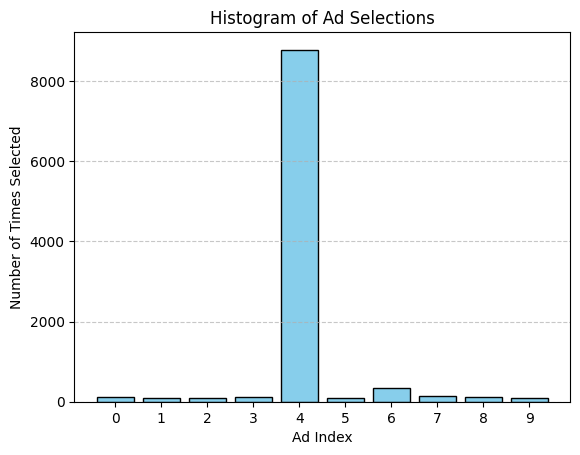

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

dataset = pd.read_csv('Ads_CTR_Optimisation.csv')
print(dataset.describe())

N = len(dataset) # Number of rounds (rows in dataset)
d = dataset.shape[1] # Number of ads (columns in dataset)

numbers_of_selections = [0] * d
sums_of_rewards = [0] * d

ads_selected = []
total_rewards = 0

epsilon = 0.1

# mean_rewards line is not used in a standard Epsilon-Greedy algorithm
# as means are estimated dynamically.
# mean_rewards = dataset.describe().loc['mean'].values

for n in range(0, N):
  ad = 0

  if random.random() < epsilon: # Exploration
    ad = random.randrange(d)
  else: # Exploitation
    max_estimated_reward = -1
    chosen_ad = 0
    for i in range(d):
      if numbers_of_selections[i] > 0:
        estimated_reward = sums_of_rewards[i] / numbers_of_selections[i]
      else:
        estimated_reward = float('inf') # Optimistic initial values

      if estimated_reward > max_estimated_reward:
        max_estimated_reward = estimated_reward
        chosen_ad = i
    ad = chosen_ad

  ads_selected.append(ad)

  reward = dataset.iloc[n, ad]
  numbers_of_selections[ad] += 1
  sums_of_rewards[ad] += reward
  total_rewards += reward

print(f"\nTotal rewards: {total_rewards}")
print(f"Selections per ad: {numbers_of_selections}")

plt.hist(ads_selected, bins=np.arange(d + 1) - 0.5, rwidth=0.8, color='skyblue', edgecolor='black')
plt.title('Histogram of Ad Selections')
plt.xlabel('Ad Index')
plt.ylabel('Number of Times Selected')
plt.xticks(range(d))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()